# TerminalBench 2.1 Luna semantic clustering

This notebook performs two parallel semantic-clustering experiments on the completed Luna decision events:

1. **Decision label + decision summary**
2. **Decision label only**

Both experiments use the same semantic embedding model, K-means configuration, candidate cluster counts, and visualization settings. No TF-IDF, keyword vectorization, trajectory extraction, or text generation is performed.

## Method

The existing free-text decisions are embedded with `qwen3-embedding:0.6b` through Ollama's embedding endpoint. The resulting vectors are L2-normalized and clustered in their complete semantic space.

Candidate solutions from k = 8 to k = 20 are evaluated with inertia and cosine silhouette score. The solutions for k = 8, 9, and 10 are then compared with PCA, t-SNE, and UMAP. These projections are visualization tools only and do not determine cluster membership.

In [15]:
from __future__ import annotations

import hashlib
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import umap.umap_ as umap
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.max_rows', 120)
plt.style.use('seaborn-v0_8-whitegrid')
print('Imports complete.')

Imports complete.


## Configuration

Ollama must be running only when an embedding cache does not yet exist. Start the Ollama desktop application or run `ollama serve`. If the embedding model is missing, run `ollama pull qwen3-embedding:0.6b`.

In [16]:
SEED = 42
MIN_K = 8
MAX_K = 20
FOCUS_K = (8, 9, 10)

OLLAMA_BASE_URL = os.getenv('OLLAMA_BASE_URL', 'http://localhost:11434').rstrip('/')
EMBEDDING_MODEL = 'qwen3-embedding:0.6b'
EMBEDDING_BATCH_SIZE = 64
EMBEDDING_TIMEOUT_SECONDS = 1_800

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'outputs').exists():
            return candidate
        nested_project = candidate / 'design-decisions-by-LLMs'
        if (nested_project / 'pyproject.toml').exists() and (nested_project / 'outputs').exists():
            return nested_project
    raise FileNotFoundError('Run this notebook from inside the design-decisions-by-LLMs project.')

PROJECT_ROOT = find_project_root(Path.cwd())
INPUT_DIR = PROJECT_ROOT / 'outputs' / 'gpt56_luna_open_coding'
INPUT_PATH = INPUT_DIR / 'decision_events.csv'
OUTPUT_DIR = INPUT_DIR / 'semantic_clustering_k8_plus'
FIGURE_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print('Input:', INPUT_PATH)
print('Outputs:', OUTPUT_DIR)

Input: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\gpt56_luna_open_coding\decision_events.csv
Outputs: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\gpt56_luna_open_coding\semantic_clustering_k8_plus


## Load the completed decision events

Every row is one extracted design-decision event. Repeated labels remain separate because each row represents evidence from a particular trajectory.

In [17]:
REQUIRED_COLUMNS = {
    'trajectory_id', 'task_id', 'model', 'harness', 'decision_number',
    'source_steps', 'decision_summary', 'decision_type_label', 'visibility',
}

decisions_df = pd.read_csv(INPUT_PATH, keep_default_na=False)
missing_columns = REQUIRED_COLUMNS - set(decisions_df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

def clean_text(value: str) -> str:
    return re.sub(r'\s+', ' ', str(value or '')).strip()

decisions_df = decisions_df.copy()
decisions_df['decision_type_label'] = decisions_df['decision_type_label'].map(clean_text)
decisions_df['decision_summary'] = decisions_df['decision_summary'].map(clean_text)
blank_mask = decisions_df['decision_type_label'].eq('')
if blank_mask.any():
    print(f'Dropping {int(blank_mask.sum())} rows with an empty decision label.')
    decisions_df = decisions_df.loc[~blank_mask].copy()

audit = pd.Series({
    'decision events': len(decisions_df),
    'contributing trajectories': decisions_df['trajectory_id'].nunique(),
    'tasks': decisions_df['task_id'].nunique(),
    'models': decisions_df['model'].nunique(),
    'harnesses (non-empty)': decisions_df.loc[decisions_df['harness'].ne(''), 'harness'].nunique(),
    'unique decision labels': decisions_df['decision_type_label'].str.lower().nunique(),
})
display(audit.to_frame('count'))
display(decisions_df.head(5))

,count
decision events,363
contributing trajectories,329
tasks,87
models,17
harnesses (non-empty),2
unique decision labels,295


,trajectory_id,task_id,model,harness,decision_number,source_steps,decision_summary,decision_type_label,visibility
0,tbench21:002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,openai/gpt-5.5,,1,0;1;2;3;4;5;6;7;8;9;10;11;12;13;14;15,Combined PDF text extraction and image OCR to classify documents and summarize invoice totals.,OCR document classification,CONTEXTUAL
1,tbench21:00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-3.1-pro-preview,,1,0;1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;20;21;22;23;24;25;26;27;28;29;30;31;32;33;34;35;36;37;38;39;40;41;42;43,"Designed Golden Gate primers around the desired plasmid junction overhangs, validating the assembled sequence and calculating melting te...",junction-constrained primer design,EXPLICIT
2,tbench21:00fb5b14-09b2-5784-bf02-c8ff83652351,terminal-bench/password-recovery,gpt-5.6-terra,codex,1,1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18,"Enumerated candidate passwords against the intact CRC after the ZIP payload was damaged, recovering every checksum-valid candidate rathe...",checksum-guided credential recovery,EXPLICIT
3,tbench21:02313bb6-612f-5dee-ac09-932b84d2ccb0,terminal-bench/adaptive-rejection-sampler,gpt-5.6-terra,codex,1,3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;20;21;22;23;24;25;26;27;28;29;30;31;32;33;34,"Implemented adaptive rejection sampling with tangent envelopes, squeeze bounds, and hull refinement, using concavity structure to reduce...",adaptive envelope sampling,EXPLICIT
4,tbench21:030137e7-3a8f-5815-875f-fd03346269d7,terminal-bench/modernize-scientific-stack,openai/muse-spark-1.1,,1,0;1;2;3;4;5;6;7;8;9,"Modernized climate analysis for current Python using pathlib, configparser, and UTF-8 CSV loading while retaining station mean calculati...",legacy climate pipeline modernization,EXPLICIT


## Create or load semantic embeddings

Two independent embedding caches are maintained. A fingerprint of the model and input text prevents stale vectors from being reused after labels or summaries change. The service check produces a short corrective message instead of a long connection traceback.

In [18]:
def require_ollama_embedding_model() -> list[str]:
    try:
        response = requests.get(f'{OLLAMA_BASE_URL}/api/tags', timeout=10)
        response.raise_for_status()
    except requests.RequestException as exc:
        raise RuntimeError(
            'Ollama is not reachable at http://localhost:11434. '
            'Start the Ollama desktop application or run `ollama serve`, then rerun this cell.'
        ) from exc

    available_models = sorted(
        model.get('name', '') for model in response.json().get('models', [])
    )
    if EMBEDDING_MODEL not in available_models:
        raise RuntimeError(
            f'Embedding model {EMBEDDING_MODEL!r} is not installed. '
            f'Run `ollama pull {EMBEDDING_MODEL}` and rerun this cell. '
            f'Available models: {available_models}'
        )
    return available_models

def embed_texts_with_cache(texts, cache_stem):
    texts = [clean_text(text) for text in texts]
    fingerprint_source = EMBEDDING_MODEL + '\n' + '\n'.join(texts)
    fingerprint = hashlib.sha256(fingerprint_source.encode('utf-8')).hexdigest()
    embedding_path = OUTPUT_DIR / f'{cache_stem}.npy'
    manifest_path = OUTPUT_DIR / f'{cache_stem}_manifest.json'

    cached_manifest = None
    if embedding_path.exists() and manifest_path.exists():
        cached_manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    if cached_manifest and cached_manifest.get('fingerprint') == fingerprint:
        cached_embeddings = np.load(embedding_path)
        if len(cached_embeddings) == len(texts):
            print(f'Loaded {cache_stem}:', cached_embeddings.shape)
            return cached_embeddings

    require_ollama_embedding_model()
    batches = []
    for start in tqdm(range(0, len(texts), EMBEDDING_BATCH_SIZE), desc=f'Embedding {cache_stem}'):
        try:
            response = requests.post(
                f'{OLLAMA_BASE_URL}/api/embed',
                json={
                    'model': EMBEDDING_MODEL,
                    'input': texts[start:start + EMBEDDING_BATCH_SIZE],
                    'truncate': False,
                },
                timeout=EMBEDDING_TIMEOUT_SECONDS,
            )
            response.raise_for_status()
        except requests.RequestException as exc:
            raise RuntimeError(
                f'Embedding request failed for rows {start}–{min(start + EMBEDDING_BATCH_SIZE, len(texts)) - 1}.'
            ) from exc
        batch = np.asarray(response.json().get('embeddings', []), dtype=np.float32)
        if len(batch) != len(texts[start:start + EMBEDDING_BATCH_SIZE]):
            raise RuntimeError('The embedding endpoint returned an unexpected number of vectors.')
        batches.append(batch)

    embeddings = np.vstack(batches)
    if not np.isfinite(embeddings).all():
        raise ValueError('The embedding matrix contains non-finite values.')
    np.save(embedding_path, embeddings)
    manifest_path.write_text(
        json.dumps({
            'fingerprint': fingerprint,
            'embedding_model': EMBEDDING_MODEL,
            'n_events': len(texts),
            'dimensions': int(embeddings.shape[1]),
        }, indent=2),
        encoding='utf-8',
    )
    print(f'Saved {cache_stem}:', embeddings.shape)
    return embeddings

In [20]:
label_summary_texts = (
    'Represent this software-agent design decision for semantic clustering. '
    'Decision type: ' + decisions_df['decision_type_label']
    + '. Decision description: ' + decisions_df['decision_summary']
).tolist()
label_only_texts = (
    'Represent this software-agent design decision for semantic clustering. '
    'Decision type: ' + decisions_df['decision_type_label']
).tolist()

label_summary_embeddings = embed_texts_with_cache(
    label_summary_texts, 'label_summary_semantic_embeddings',
)
label_only_embeddings = embed_texts_with_cache(
    label_only_texts, 'label_only_semantic_embeddings',
)

X_label_summary = normalize(label_summary_embeddings)
X_label_only = normalize(label_only_embeddings)
REPRESENTATIONS = {
    'label_summary': {
        'title': 'Decision label + summary',
        'matrix': X_label_summary,
        'color': '#287d7a',
    },
    'label_only': {
        'title': 'Decision label only',
        'matrix': X_label_only,
        'color': '#6f4e9c',
    },
}

display(pd.DataFrame({
    'representation': [value['title'] for value in REPRESENTATIONS.values()],
    'events': [len(value['matrix']) for value in REPRESENTATIONS.values()],
    'dimensions': [value['matrix'].shape[1] for value in REPRESENTATIONS.values()],
}))

Embedding label_summary_semantic_embeddings: 100%|██████████| 6/6 [00:23<00:00,  3.85s/it]


Saved label_summary_semantic_embeddings: (363, 1024)


Embedding label_only_semantic_embeddings: 100%|██████████| 6/6 [00:20<00:00,  3.47s/it]

Saved label_only_semantic_embeddings: (363, 1024)


,representation,events,dimensions
0,Decision label + summary,363,1024
1,Decision label only,363,1024


## Elbow and silhouette diagnostics

The same candidate values and random seed are used for both semantic representations. The metrics support comparison but do not automatically define the final taxonomy.

In [21]:
def fit_candidate_models(X, representation_name):
    upper_k = min(MAX_K, len(X) - 1)
    candidate_k = list(range(MIN_K, upper_k + 1))
    if not set(FOCUS_K).issubset(candidate_k):
        raise ValueError('The dataset is too small for k = 8, 9, and 10.')
    models = {}
    rows = []
    for k in tqdm(candidate_k, desc=f'Clustering {representation_name}'):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=50)
        labels = model.fit_predict(X)
        models[k] = model
        sizes = np.bincount(labels)
        rows.append({
            'representation': representation_name,
            'k': k,
            'inertia': float(model.inertia_),
            'silhouette_cosine': float(silhouette_score(X, labels, metric='cosine')),
            'smallest_cluster': int(sizes.min()),
            'largest_cluster': int(sizes.max()),
        })
    return models, pd.DataFrame(rows)

models_by_representation = {}
metric_frames = []
for representation_name, config in REPRESENTATIONS.items():
    models, metrics = fit_candidate_models(config['matrix'], representation_name)
    models_by_representation[representation_name] = models
    metric_frames.append(metrics)

metrics_df = pd.concat(metric_frames, ignore_index=True)
metrics_df.to_csv(OUTPUT_DIR / 'semantic_cluster_count_metrics.csv', index=False)
display(metrics_df)

Clustering label_only: 100%|██████████| 13/13 [00:20<00:00,  1.54s/it]


,representation,k,inertia,silhouette_cosine,smallest_cluster,largest_cluster
0,label_summary,8,78.214119,0.125302,11,91
1,label_summary,9,76.621140,0.121512,12,78
2,label_summary,10,75.358505,0.121585,10,81
3,label_summary,11,74.303078,0.137835,12,62
4,label_summary,12,72.706009,0.135456,8,65
5,label_summary,13,71.380569,0.133230,9,78
6,label_summary,14,69.846786,0.147714,7,54
7,label_summary,15,68.939117,0.152479,4,66
8,label_summary,16,67.865120,0.152954,4,57
9,label_summary,17,66.742622,0.173772,7,51


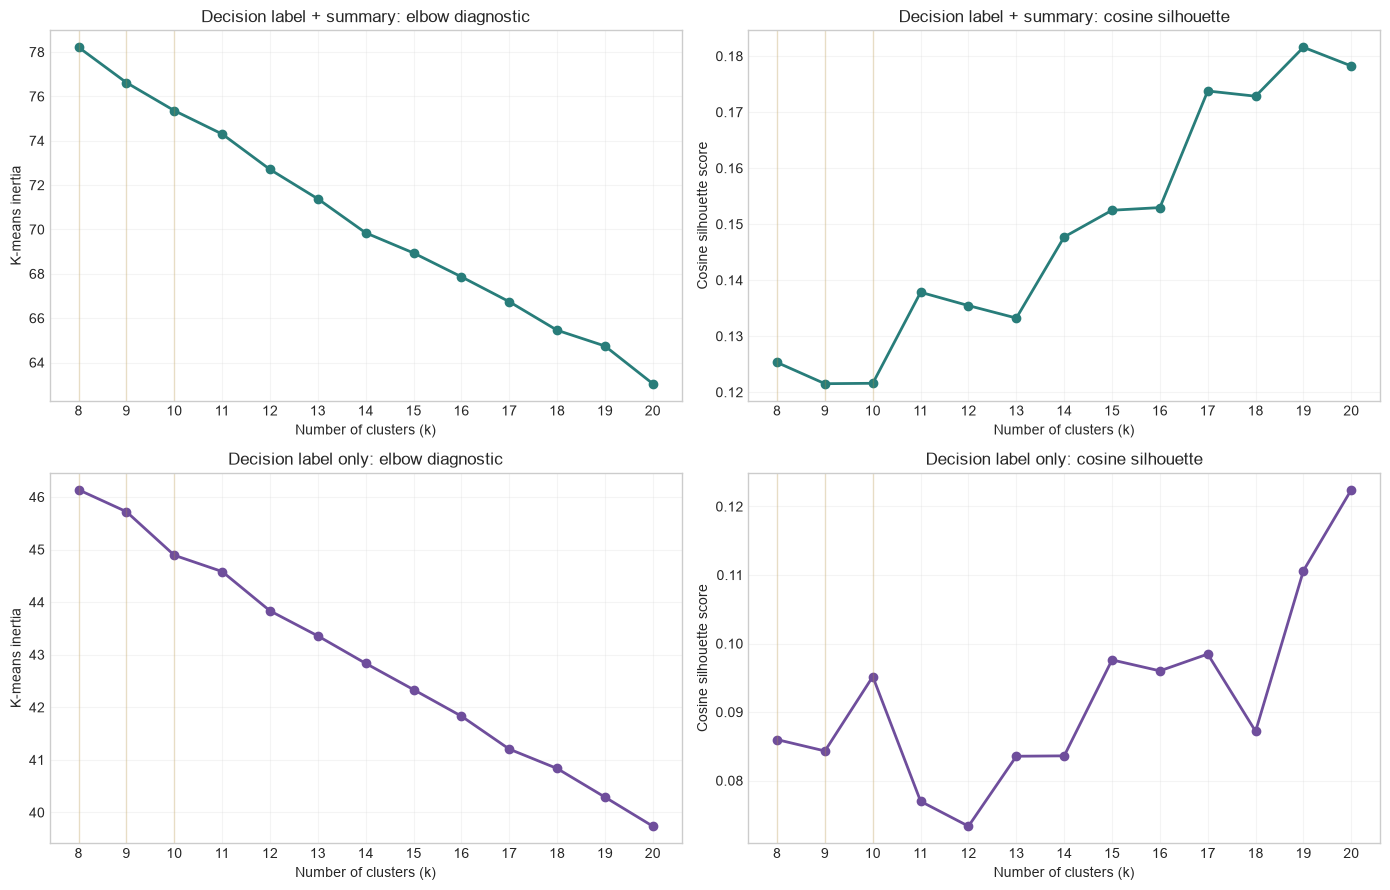

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (representation_name, config) in enumerate(REPRESENTATIONS.items()):
    subset = metrics_df.loc[metrics_df['representation'].eq(representation_name)]
    axes[row, 0].plot(subset['k'], subset['inertia'], marker='o', color=config['color'], linewidth=2)
    axes[row, 0].set_title(f"{config['title']}: elbow diagnostic")
    axes[row, 0].set_ylabel('K-means inertia')
    axes[row, 1].plot(
        subset['k'], subset['silhouette_cosine'], marker='o',
        color=config['color'], linewidth=2,
    )
    axes[row, 1].set_title(f"{config['title']}: cosine silhouette")
    axes[row, 1].set_ylabel('Cosine silhouette score')
    for ax in axes[row]:
        for k in FOCUS_K:
            ax.axvline(k, color='#c49a3a', alpha=.25, linewidth=1)
        ax.set_xlabel('Number of clusters (k)')
        ax.set_xticks(subset['k'])
        ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'semantic_elbow_and_silhouette.png', dpi=180, bbox_inches='tight')
plt.show()

## Focused comparison: k = 8, 9, and 10

Assignments for both semantic representations are stored together. Adjusted Rand Index measures how similarly the two input formulations partition the same decision events.

In [23]:
assignments_df = decisions_df.copy()
agreement_rows = []
for representation_name in REPRESENTATIONS:
    for k in FOCUS_K:
        assignments_df[f'{representation_name}_cluster_k{k}'] = (
            models_by_representation[representation_name][k].labels_
        )
for k in FOCUS_K:
    agreement_rows.append({
        'k': k,
        'adjusted_rand_label_summary_vs_label_only': adjusted_rand_score(
            assignments_df[f'label_summary_cluster_k{k}'],
            assignments_df[f'label_only_cluster_k{k}'],
        ),
    })
agreement_df = pd.DataFrame(agreement_rows)
assignments_df.to_csv(OUTPUT_DIR / 'semantic_cluster_assignments_k8_k9_k10.csv', index=False)
agreement_df.to_csv(OUTPUT_DIR / 'semantic_representation_agreement.csv', index=False)
display(agreement_df)

,k,adjusted_rand_label_summary_vs_label_only
0,8,0.278715
1,9,0.214637
2,10,0.319014


In [24]:
def plot_focus_projections(points, representation_name, method):
    title = REPRESENTATIONS[representation_name]['title']
    fig, axes = plt.subplots(1, len(FOCUS_K), figsize=(19, 5.5), sharex=True, sharey=True)
    for ax, k in zip(axes, FOCUS_K):
        labels = models_by_representation[representation_name][k].labels_
        colors = list(plt.get_cmap('tab10').colors[:k])
        cmap = ListedColormap(colors)
        norm = BoundaryNorm(np.arange(-.5, k + .5, 1), cmap.N)
        scatter = ax.scatter(
            points[:, 0], points[:, 1], c=labels, cmap=cmap, norm=norm,
            s=30, alpha=.78, linewidths=0,
        )
        ax.set_title(f'{method}: k = {k}')
        ax.set_xlabel(f'{method} dimension 1')
        ax.set_ylabel(f'{method} dimension 2')
        ax.grid(alpha=.14)
        colorbar = fig.colorbar(scatter, ax=ax, ticks=np.arange(k), fraction=.047, pad=.03)
        colorbar.set_label('K-means cluster')
    fig.suptitle(f'{title} — {method} views', fontsize=15, y=1.02)
    plt.tight_layout()
    filename = f'{representation_name}_{method.lower().replace("-", "")}_k8_k9_k10.png'
    plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

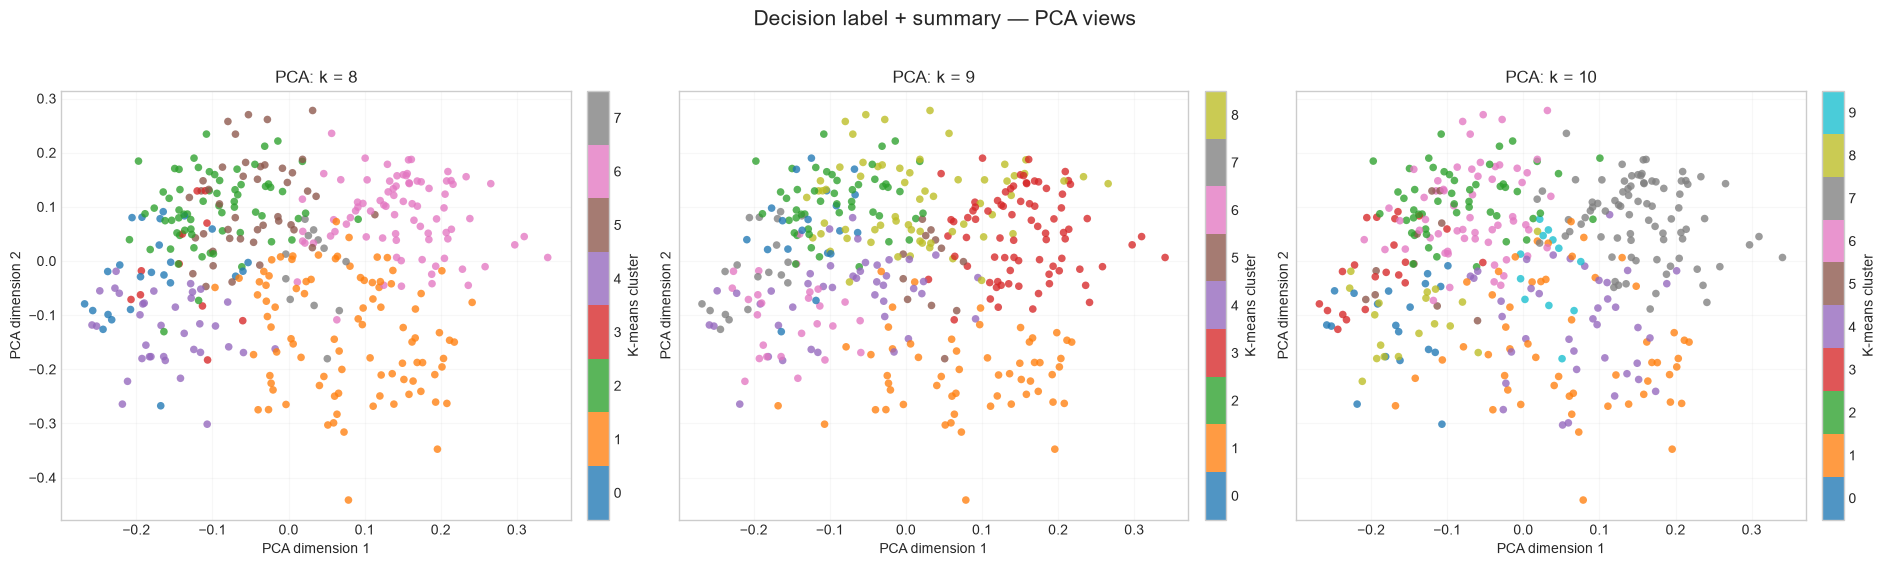

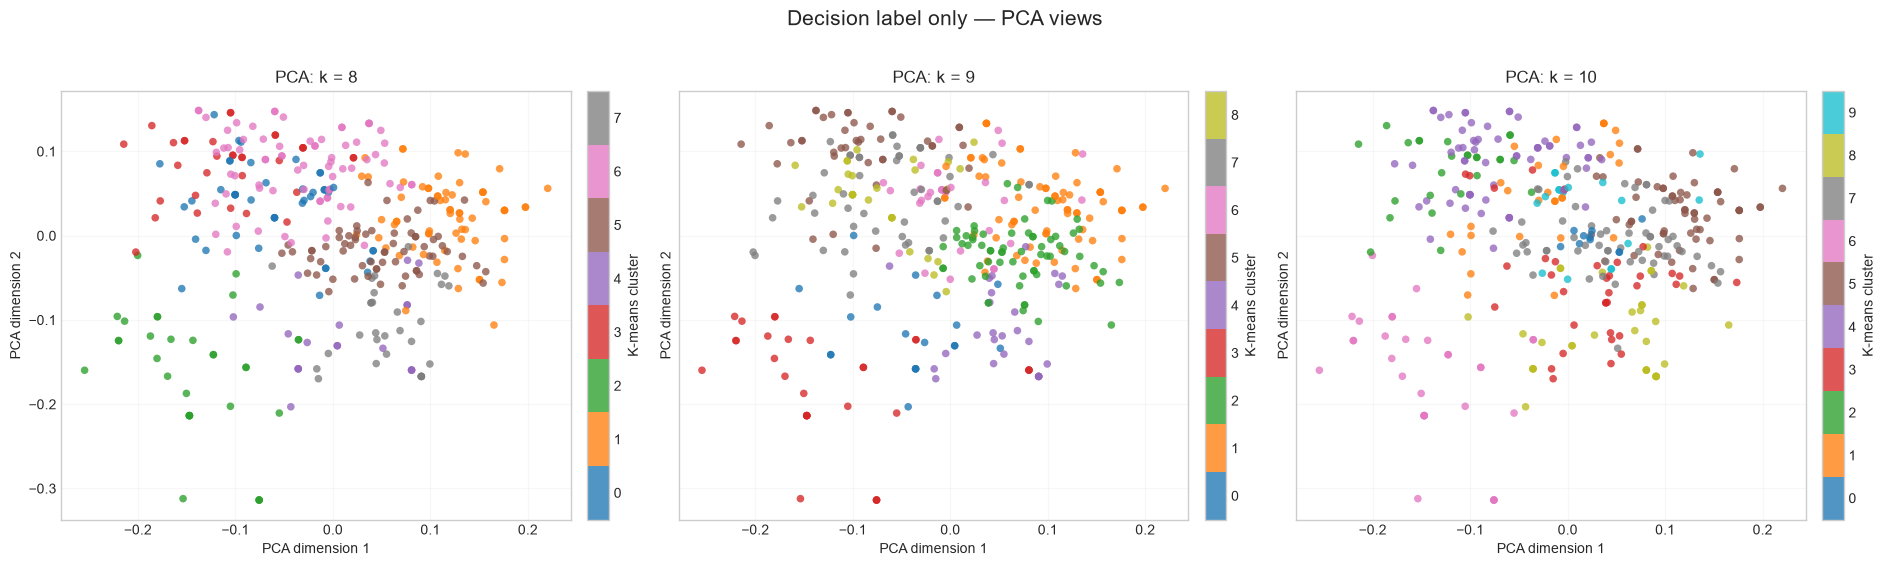

In [25]:
for representation_name, config in REPRESENTATIONS.items():
    pca_points = PCA(n_components=2, random_state=SEED).fit_transform(config['matrix'])
    plot_focus_projections(pca_points, representation_name, 'PCA')

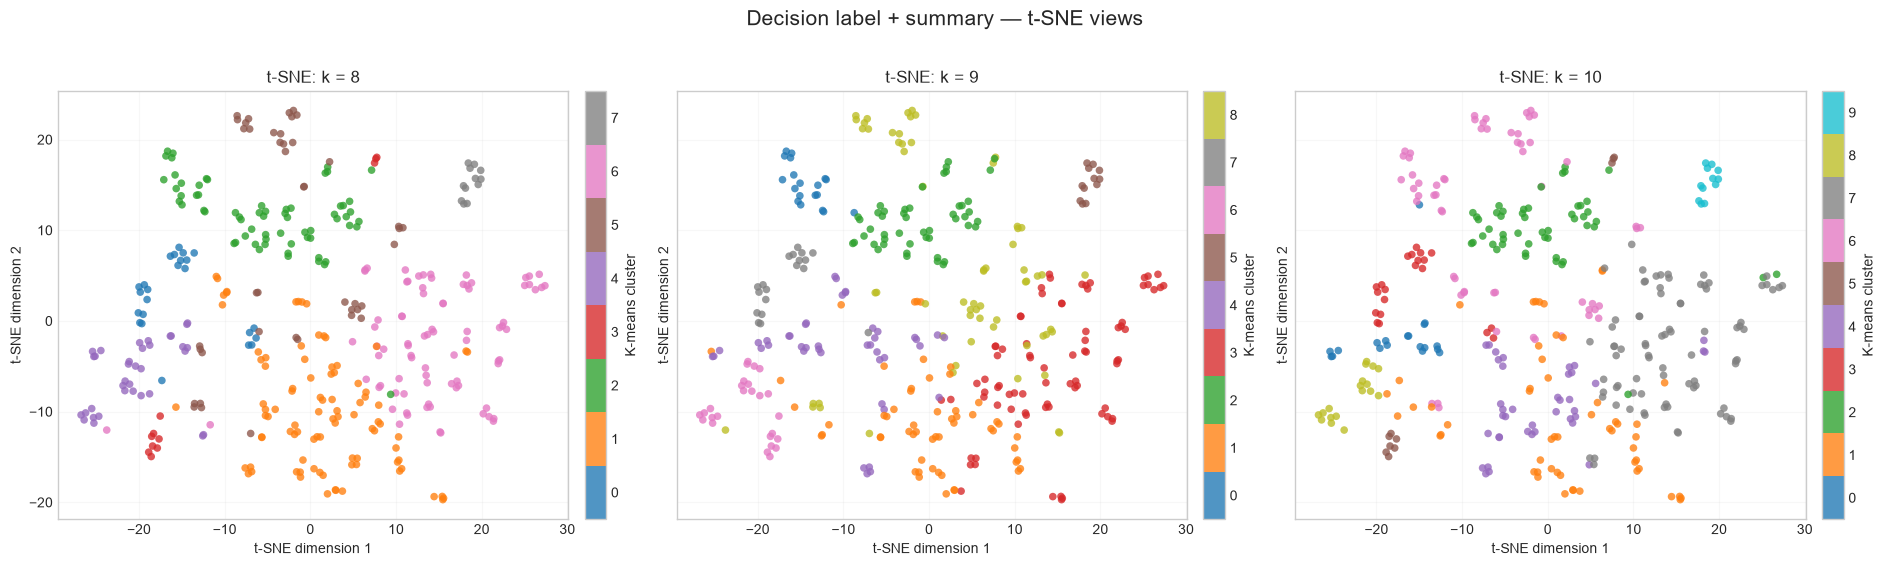

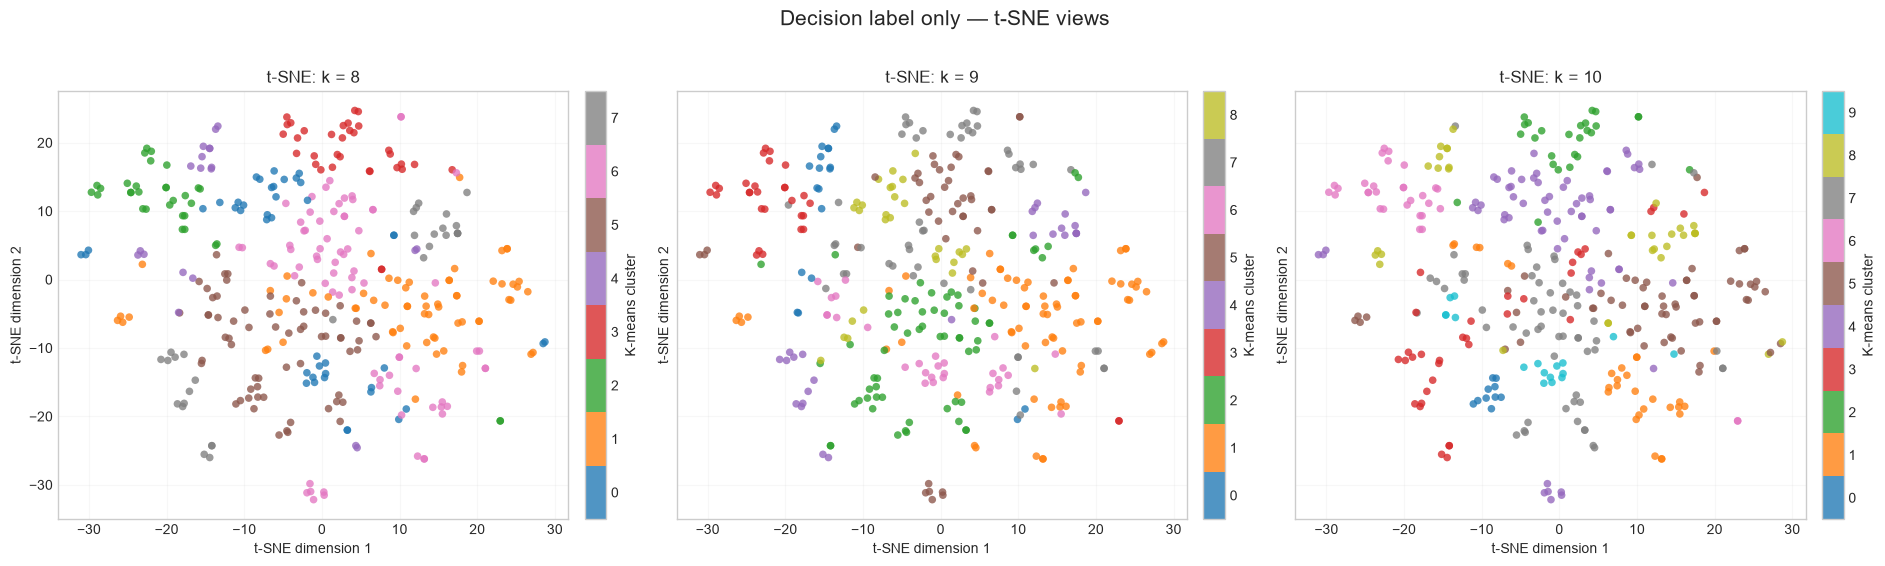

In [26]:
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    reduced_dimensions = min(50, X.shape[1], len(X) - 1)
    tsne_input = PCA(n_components=reduced_dimensions, random_state=SEED).fit_transform(X)
    perplexity = min(30, max(5, (len(X) - 1) // 3))
    tsne_points = TSNE(
        n_components=2, perplexity=perplexity, init='pca',
        learning_rate='auto', max_iter=1_000, random_state=SEED,
    ).fit_transform(tsne_input)
    plot_focus_projections(tsne_points, representation_name, 't-SNE')

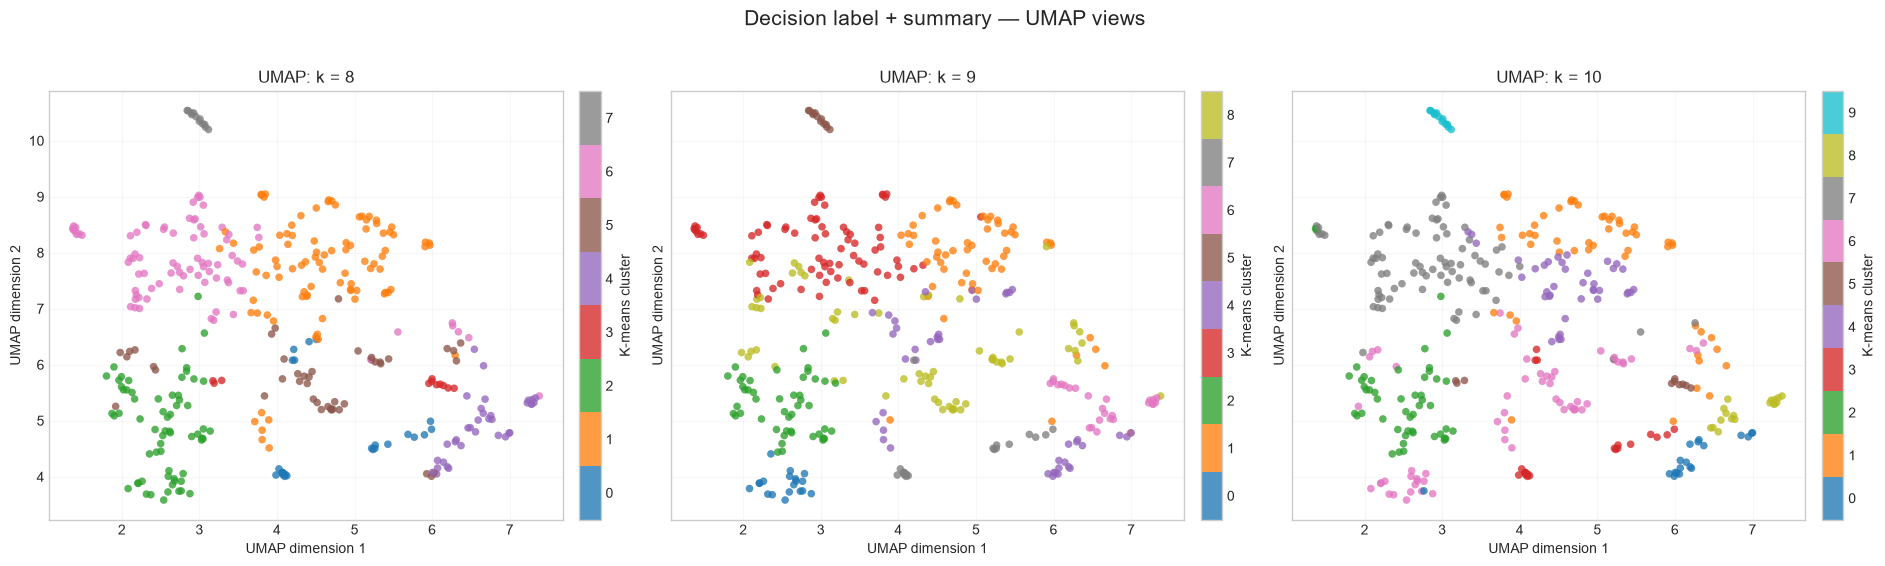

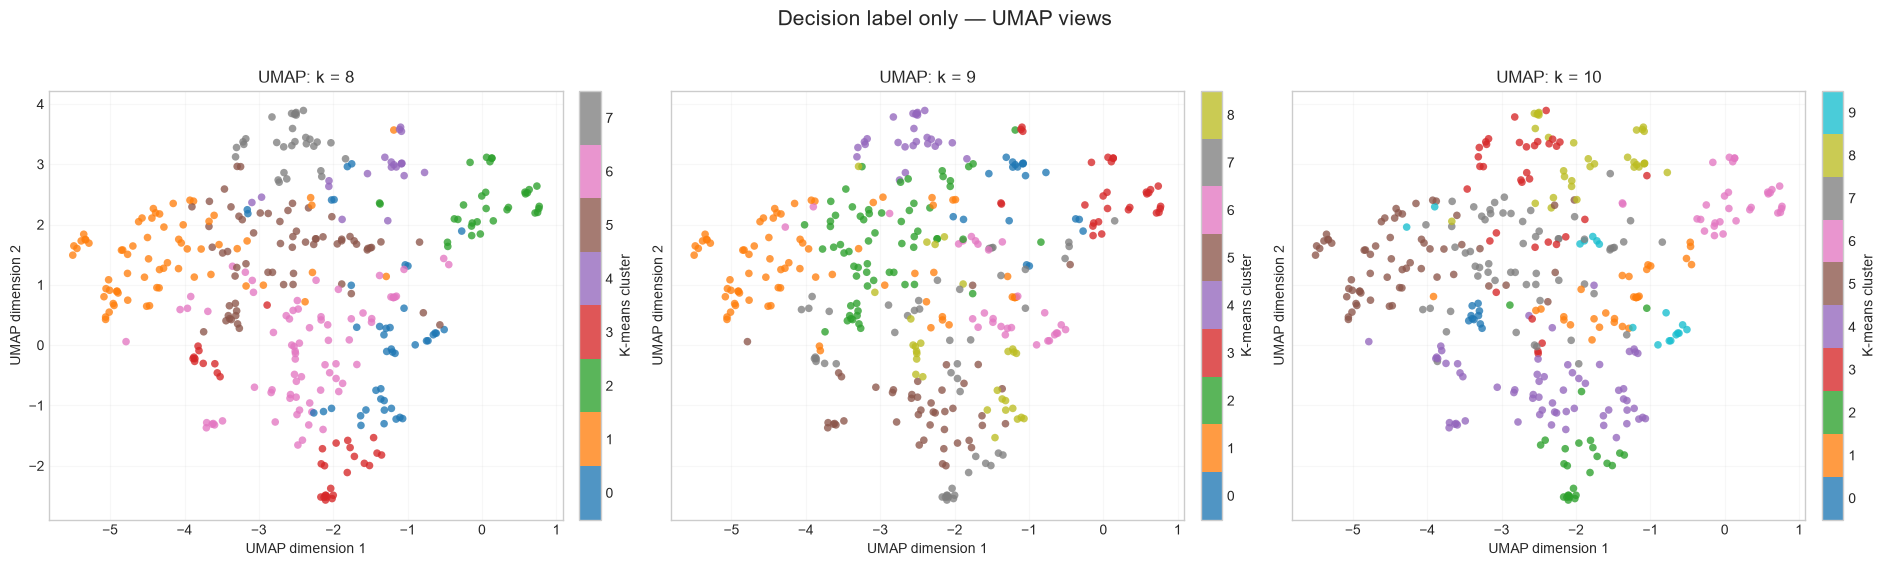

In [27]:
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    umap_points = umap.UMAP(
        n_components=2, n_neighbors=min(30, len(X) - 1), min_dist=.10,
        metric='cosine', random_state=SEED, n_jobs=1,
    ).fit_transform(X)
    plot_focus_projections(umap_points, representation_name, 'UMAP')

## Cluster summaries and representative events

For every representation and focused k, the output contains cluster sizes, frequent labels, and the five events closest to each centroid. These records—not the scatter plots alone—should be used to judge semantic coherence.

In [28]:
summary_tables = {}
for representation_name, config in REPRESENTATIONS.items():
    X = config['matrix']
    for k in FOCUS_K:
        model = models_by_representation[representation_name][k]
        cluster_column = f'{representation_name}_cluster_k{k}'
        working = assignments_df.copy()
        distances = model.transform(X)
        working['distance_to_centroid'] = distances[
            np.arange(len(working)), working[cluster_column].to_numpy(),
        ]
        summary_rows = []
        representative_parts = []
        for cluster_id, group in working.groupby(cluster_column, sort=True):
            frequent_labels = group['decision_type_label'].value_counts().head(8)
            summary_rows.append({
                'cluster': int(cluster_id),
                'n_events': len(group),
                'n_trajectories': group['trajectory_id'].nunique(),
                'n_tasks': group['task_id'].nunique(),
                'top_labels': ' | '.join(
                    f'{label} ({count})' for label, count in frequent_labels.items()
                ),
            })
            representative_parts.append(group.nsmallest(5, 'distance_to_centroid'))
        summary_df = pd.DataFrame(summary_rows)
        representatives_df = pd.concat(representative_parts, ignore_index=True)
        summary_df.to_csv(
            OUTPUT_DIR / f'{representation_name}_cluster_summary_k{k}.csv', index=False,
        )
        representatives_df.to_csv(
            OUTPUT_DIR / f'{representation_name}_cluster_representatives_k{k}.csv', index=False,
        )
        summary_tables[(representation_name, k)] = summary_df
        print(f"{config['title']} — k = {k}")
        display(summary_df)

Decision label + summary — k = 8


,cluster,n_events,n_trajectories,n_tasks,top_labels
0,0,24,22,6,orphaned change integration (4) | conflict resolution precedence (2) | conflict resolution strategy (2) | branch deployment automation (...
1,1,91,89,29,service configuration strategy (3) | historical coverage filtering (2) | graph structure inference (2) | keystroke budget optimization (...
2,2,65,60,19,cross-language source encoding (2) | cross-language implementation strategy (2) | legacy interface modernization (2) | platform compatib...
3,3,11,11,3,legacy record semantics emulation (3) | database log recovery (3) | low-level data recovery (2) | truncated database page decoding (1) |...
4,4,35,35,10,credential recovery method (4) | linear cryptanalysis key recovery (3) | targeted secret remediation (2) | byte-level digest constructio...
5,5,43,37,15,binary memory image reconstruction (4) | allocator lifecycle stabilization (3) | content-level layout repair (2) | simulator timing expl...
6,6,82,72,21,physics-preserving solver tuning (3) | black-box parameter recovery (3) | constrained parameter adaptation (3) | pipeline stage partitio...
7,7,12,12,3,insertion primer temperature matching (2) | junction-constrained primer design (1) | plasmid junction mapping (1) | scarless junction pr...


Decision label + summary — k = 9


,cluster,n_events,n_trajectories,n_tasks,top_labels
0,0,19,15,5,execution mode fallback (2) | virtual machine startup orchestration (1) | headless simulator build (1) | interactive shell emulation (1)...
1,1,56,56,26,byte-level digest construction (2) | prompted mask refinement (2) | calendar constraint parsing (2) | OCR document classification (1) | ...
2,2,48,47,15,cross-language source encoding (2) | cross-language implementation strategy (2) | legacy interface modernization (2) | platform compatib...
3,3,78,69,22,physics-preserving solver tuning (3) | black-box parameter recovery (3) | constrained parameter adaptation (3) | constraint-aware batch ...
4,4,42,42,15,service configuration strategy (3) | targeted secret remediation (2) | conflict resolution precedence (2) | content-level layout repair ...
5,5,12,12,3,insertion primer temperature matching (2) | junction-constrained primer design (1) | plasmid junction mapping (1) | scarless junction pr...
6,6,26,26,7,credential recovery method (4) | linear cryptanalysis key recovery (3) | database log recovery (3) | low-level data recovery (2) | fragm...
7,7,19,19,5,orphaned change integration (4) | branch deployment automation (2) | push-triggered deployment strategy (2) | branch deployment isolatio...
8,8,63,55,23,binary memory image reconstruction (4) | allocator lifecycle stabilization (3) | numerical call overhead reduction (2) | legacy record s...


Decision label + summary — k = 10


...

,cluster,n_events,n_trajectories,n_tasks,top_labels
0,0,43,41,14,orphaned change integration (4) | legacy record semantics emulation (3) | conflict resolution precedence (2) | legacy interface moderniz...
1,1,67,64,25,physics-preserving solver tuning (3) | constrained parameter adaptation (3) | constraint-aware batch optimization (2) | constrained dist...
2,2,32,32,11,credential recovery method (4) | linear cryptanalysis key recovery (3) | targeted secret remediation (2) | byte-level digest constructio...
3,3,33,33,13,service configuration strategy (3) | empirical configuration selection (2) | branch deployment automation (2) | push-triggered deploymen...
4,4,20,20,10,black-box parameter recovery (3) | database log recovery (3) | low-level data recovery (2) | fragmented data reconstruction (2) | trunca...
5,5,64,62,26,historical coverage filtering (2) | graph structure inference (2) | bounded and atomic reconstruction (2) | calendar constraint parsing ...
6,6,74,69,30,allocator lifecycle stabilization (3) | pipeline stage partitioning (2) | cross-language source encoding (2) | cross-language implementa...
7,7,30,30,12,binary memory image reconstruction (4) | prompted mask refinement (2) | OCR document classification (1) | distributed forward reconstruc...


Decision label only — k = 9


,cluster,n_events,n_trajectories,n_tasks,top_labels
0,0,19,19,10,database log recovery (3) | low-level data recovery (2) | forensic recovery and cleanup (2) | constrained log pattern matching (1) | gar...
1,1,73,68,25,allocator lifecycle stabilization (3) | physics-preserving solver tuning (3) | constrained parameter adaptation (3) | constraint-aware b...
2,2,64,61,31,content-level layout repair (2) | graph structure inference (2) | prompted mask refinement (2) | query execution restructuring (2) | bou...
3,3,30,30,11,credential recovery method (4) | linear cryptanalysis key recovery (3) | black-box parameter recovery (3) | targeted secret remediation ...
4,4,26,26,11,binary memory image reconstruction (4) | OCR document classification (1) | image-to-code OCR (1) | toolpath text reconstruction (1) | in...
5,5,44,43,16,cross-language source encoding (2) | cross-language implementation strategy (2) | platform compatibility strategy (2) | compiler depende...
6,6,29,26,13,conflict resolution precedence (2) | conflict resolution strategy (2) | calendar constraint parsing (2) | invoice field precedence (1) |...
7,7,49,47,25,service configuration strategy (3) | pipeline stage partitioning (2) | historical coverage filtering (2) | execution mode fallback (2) |...
8,8,29,29,14,orphaned change integration (4) | legacy record semantics emulation (3) | legacy interface modernization (2) | legacy climate pipeline m...


Decision label only — k = 10


,cluster,n_events,n_trajectories,n_tasks,top_labels
0,0,10,10,3,insertion primer temperature matching (2) | junction-constrained primer design (1) | plasmid junction mapping (1) | scarless junction pr...
1,1,29,26,10,allocator lifecycle stabilization (3) | simulator timing exploitation (2) | autograd-safe communication (2) | runtime resource finalizat...
2,2,26,26,10,branch deployment automation (2) | push-triggered deployment strategy (2) | branch deployment isolation (2) | instrumented build deploym...
3,3,35,35,16,prompted mask refinement (2) | OCR document classification (1) | special-case chess move encoding (1) | image-to-code OCR (1) | toolpath...
4,4,63,60,23,orphaned change integration (4) | legacy record semantics emulation (3) | service configuration strategy (3) | cross-language source enc...
5,5,61,58,22,physics-preserving solver tuning (3) | constrained parameter adaptation (3) | constraint-aware batch optimization (2) | constrained dist...
6,6,31,31,11,credential recovery method (4) | linear cryptanalysis key recovery (3) | targeted secret remediation (2) | byte-level digest constructio...
7,7,58,56,28,pipeline stage partitioning (2) | historical coverage filtering (2) | graph structure inference (2) | query execution restructuring (2) ...
8,8,33,32,15,binary memory image reconstruction (4) | black-box parameter recovery (3) | database log recovery (3) | low-level data recovery (2) | co...
9,9,17,17,8,conflict resolution precedence (2) | conflict resolution strategy (2) | calendar constraint parsing (2) | invoice field precedence (1) |...


## Generated outputs

All new files are written under `outputs/gpt56_luna_open_coding/semantic_clustering_k8_plus/`. Existing keyword-based output files are left untouched but are not read by this notebook.

- separate cached semantic embeddings for label-plus-summary and label-only;
- elbow and silhouette metrics for both representations;
- k = 8, 9, and 10 assignments for both representations;
- Adjusted Rand agreement between the two representations;
- PCA, t-SNE, and UMAP figures for both representations; and
- cluster summaries and centroid-nearest representative events.

## Interpretation order

1. Compare silhouette and cluster-size balance across k.
2. Check whether label-plus-summary and label-only produce similar partitions.
3. Inspect centroid-nearest events and frequent labels for conceptual coherence.
4. Check whether apparent clusters occur across several tasks rather than reflecting one task family.
5. Treat a cluster as provisional only when quantitative separation, stability, and qualitative interpretation agree.